## Convert to PyTorch tensors

In [1]:
import numpy as np

import torch
from torch.utils.data import TensorDataset, DataLoader


In [2]:
X_train_processed = np.load("../data/processed/X_train.npy")
X_val_processed = np.load("../data/processed/X_val.npy")
X_test_processed = np.load("../data/processed/X_test.npy")

y_train = np.load("../data/processed/y_train.npy")
y_val = np.load("../data/processed/y_val.npy")
y_test = np.load("../data/processed/y_test.npy")

In [5]:
type(y_train)

numpy.ndarray

In [6]:
# convert float64 to float32
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor =torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

In [7]:
m = torch.tensor([0, 1, 0, 1, 1])

print(m.shape) # 1D array. containing 5 elements(rows)
print(m)

print(m.reshape(-1, 1).shape) #2D array. containing 5 elements, and 1 column
print(m.reshape(-1, 1))


torch.Size([5])
tensor([0, 1, 0, 1, 1])
torch.Size([5, 1])
tensor([[0],
        [1],
        [0],
        [1],
        [1]])


In [8]:
print("TRAIN")
print("X:", X_train_tensor.shape)
print("y:", y_train_tensor.shape)

print("\nDTYPES")
print("X:", X_train_tensor.dtype)
print("y:", y_train_tensor.dtype)

print("\nDIMENSIONS")
print("X:", X_train_tensor.ndim)
print("y:", y_train_tensor.ndim)

print("\nDEVICE")
print("X:", X_train_tensor.device)
print("y:", y_train_tensor.device)

print("\nMEMORY")
print("X:", X_train_tensor.element_size(), "bytes per element")
print("X:", X_train_tensor.nelement() * X_train_tensor.element_size(), "bytes")

print("\nMISSING VALUES")
print("X:", torch.isnan(X_train_tensor).sum().item())
print("y:", torch.isnan(y_train_tensor).sum().item())


TRAIN
X: torch.Size([24862, 45])
y: torch.Size([24862, 1])

DTYPES
X: torch.float32
y: torch.float32

DIMENSIONS
X: 2
y: 2

DEVICE
X: cpu
y: cpu

MEMORY
X: 4 bytes per element
X: 4475160 bytes

MISSING VALUES
X: 0
y: 0


- `TensorDataset` becasue my dataset is already in NumPy arrays.
so I just converted to tensors and used `TensorDataset` instead of `Dataset`

In [9]:
X_train_tensor.shape[0]

24862

In [10]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# inspeact
print("Train batches per epoch:", X_train_tensor.shape[0] / 256, "\n")
for batch_x, batch_y in train_loader:
    print(batch_x.shape, batch_y.shape)


Train batches per epoch: 97.1171875 

torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256, 45]) torch.Size([256, 1])
torch.Size([256,

In [11]:
print("Training samples:", len(train_dataset))
print("Training batches:", len(train_loader))

batch_x, batch_y = next(iter(train_loader))

print("Feature dtype:", batch_x.dtype)
print("Label dtype:", batch_y.dtype)

print("Feature device:", batch_x.device)
print("Label device:", batch_y.device)


Training samples: 24862
Training batches: 98
Feature dtype: torch.float32
Label dtype: torch.float32
Feature device: cpu
Label device: cpu


My dataset has approximately 25,000 training samples and only 45 input features. We don't need a very large network to start learning useful patterns.

Loss function: BCEWithLogitsLoss
Because my output layer produces a raw value called a logit, not a probability.
This loss function internally applies sigmoid to convert logits into probabilities before calculating binary cross-entropy.
Becasue data is imbalanced, I would consider pos_weight in the loss function.

Optimizer: Adam

In [12]:
from torch import nn

torch.manual_seed(42)

In [13]:
class ChurnModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.LeakyReLU(),
            nn.Linear(64, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.model(x)

In [14]:
model = ChurnModel(input_dim=X_train_tensor.shape[1])

In [15]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(dataloader, model, optimizer, criterion):
    model.train()

    total_loss = 0
    total_samples = 0

    for batch_x, batch_y in dataloader:
        optimizer.zero_grad()

        logits = model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        batch_size = batch_x.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
        
    return total_loss / total_samples


In [16]:
def evaluate_loss(dataloader, model, criterion):
    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.inference_mode():
        for batch_x, batch_y in dataloader:
            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            batch_size = batch_x.size(0)
            total_loss += loss
            total_samples += batch_size

    return total_loss / total_samples


In [17]:
# full training
epochs = 10
epochs_train_loss = []
epochs_val_loss= []

for epoch in range(epochs):
    train_loss = train_one_epoch(train_loader, model, optimizer, criterion)
    val_loss = evaluate_loss(val_loader, model, criterion)

    epochs_train_loss.append(train_loss)
    epochs_val_loss.append(val_loss)

c:\Users\ecole\CoreML-Ayush\resume-projects\kkbox-churn\.venv\Lib\site-packages\torch\cuda\__init__.py:497: UserWarning: Found GPU0 NVIDIA GeForce MX330 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0
- 8.6 which supports hardware CC >=8.6,<9.0
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.15.0+cu132 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.15.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
c:\Users\ecole\CoreML-Ayush\resume-projects\kkbox-churn\.venv\Lib\site-packages\torch\cuda\__init__.py:627: UserWarning: 
NVIDIA Ge

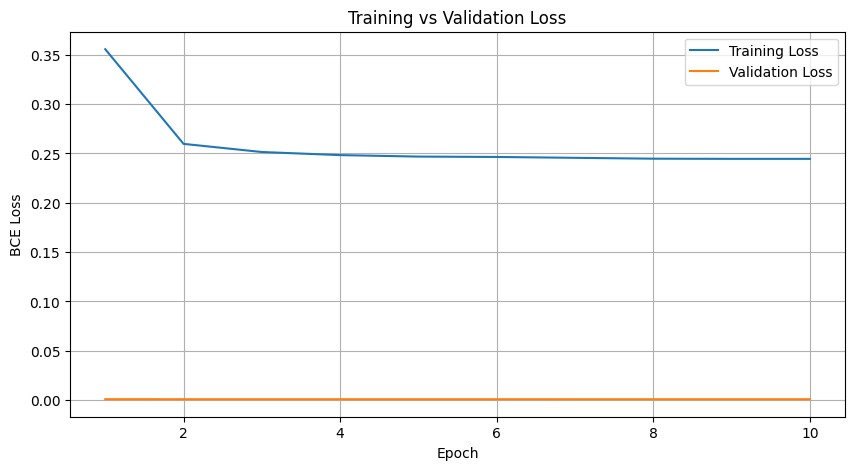

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(range(1, epochs + 1), epochs_train_loss, label="Training Loss")

plt.plot(range(1, epochs + 1), epochs_val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


In [24]:
epochs_val_loss

[tensor(0.0011),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010),
 tensor(0.0010)]

## Final Evaluation

In [19]:
def predict(x, model):
    model.eval()

    with torch.inference_mode():
        logits = model(x)
        probabilities = torch.sigmoid(logits)
    
    return probabilities

In [20]:
churn_risk_scores = predict(X_test_tensor, model)

churn_risk_scores.shape

torch.Size([5328, 1])

Since existing XGBoost benchmark uses:
- AUC-PR (Average Precision).
- Precision@100.
We should use those same metrics for the ANN.

In [21]:
from sklearn.metrics import average_precision_score

y_true = y_test_tensor.cpu().numpy().ravel()
y_scores = churn_risk_scores.cpu().numpy().ravel()

auc_pr = average_precision_score(y_true, y_scores)

# get the indeces of customers with the highest y_scores(predicted churn risk)
# np.argsort orders the list(y_scores) in ascending order, lowest to highest
# so select the last 100 indices cos that's the higest risk scores
top_100_indices = np.argsort(y_scores)[-100:][::-1]
precision_at_100 = y_true[top_100_indices].mean()

print(f"AUC-PR: {auc_pr:.4f}")
print(f"Precision@100: {precision_at_100:.4f}")

AUC-PR: 0.9773
Precision@100: 0.9900


In [22]:
scores = np.array([10, 20, 30, 40, 50])

scores[::-1]  # = array[ start : stop : step ]
# array[None:None:-1] = move backwards, one element at a time


array([50, 40, 30, 20, 10])

## Save model
- architecture + weights and bias

## Compare again ML baseline(XGBoost)

In [3]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [4]:
import joblib
import pandas as pd

preprocessor = joblib.load("preprocessor.joblib")

feature_names = preprocessor.get_feature_names_out()

train_df = pd.DataFrame(X_train_processed, columns=feature_names)
val_df = pd.DataFrame(X_val_processed, columns=feature_names)
test_df = pd.DataFrame(X_test_processed, columns=feature_names)

train_df["is_churn"] = y_train
val_df["is_churn"] = y_val
test_df["is_churn"] = y_test

In [5]:
p99_secs = 43574.0
cat_categories = {
    "last_is_auto_renew": [0, 1],
    "last_is_cancel": [0, 1],
    "ever_cancelled": [0, 1],
    "ever_promo": [0, 1],
    "registered_via": [3, 4, 7, 9, 13],
}


In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24862 entries, 0 to 24861
Data columns (total 46 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   encoder__registered_via_0.0                 24862 non-null  float64
 1   encoder__registered_via_3.0                 24862 non-null  float64
 2   encoder__registered_via_4.0                 24862 non-null  float64
 3   encoder__registered_via_7.0                 24862 non-null  float64
 4   encoder__registered_via_9.0                 24862 non-null  float64
 5   encoder__registered_via_13.0                24862 non-null  float64
 6   scale__n_txn                                24862 non-null  float64
 7   scale__n_cancel                             24862 non-null  float64
 8   scale__last_actual_amount_paid              24862 non-null  float64
 9   scale__last_payment_plan_days               24862 non-null  float64
 10  scale__las

In [7]:
from src.pipelines.train import train_candidate_model

artifact = train_candidate_model(train_df=train_df, val_df=val_df, p99_secs=p99_secs, n_estimators=500, feature_cols=feature_names)
xgb = artifact.booster

xgb_val_auc_pr = artifact.val_auc_pr
xgb_precision_at_100 = artifact.precision_at_k

14:05:26.852 | INFO    | prefect - Starting temporary server on http://127.0.0.1:8824
See https://docs.prefect.io/v3/concepts/server#how-to-guides for more information on running a dedicated Prefect server.

14:05:40.110 | INFO    | Task run 'train-candidate-model' - train_candidate_model | n_train=24862 | n_val=5328 | scale_pos_weight=0.10

14:05:41.594 | INFO    | Task run 'train-candidate-model' - train_candidate_model complete | val_auc_pr=0.9776 | val_auc_roc=0.8236 | precision@100=1.0000

C:\Users\ecole\AppData\Local\Programs\Python\Python311\Lib\logging\__init__.py:1887: UserWarning: Logger 'prefect.task_runs' attempted to send logs to the API without a flow run id. The API log handler can only send logs within flow run contexts unless the flow run id is manually provided. Set PREFECT_LOGGING_TO_API_WHEN_MISSING_FLOW=ignore to suppress this warning.
  self.logger.log(level, msg, *args, **kwargs)


14:05:41.594 | INFO    | Task run 'train-candidate-model' - Finished in state Completed()

In [15]:
import joblib

joblib.dump(artifact, "churn_xgb_model_artifact.joblib")

['churn_xgb_model_artifact.joblib']

## Final Evaluation(XGBoost)


In [14]:
from sklearn.metrics import average_precision_score

X = test_df[artifact.feature_cols]
y = test_df["is_churn"]

# Predicted probability of churn
xgb_y_scores = xgb.predict_proba(X)[:, 1]

# AUC-PR
xgb_auc_pr = average_precision_score(y, xgb_y_scores)

# Precision@100
xgb_top_100_indices = np.argsort(xgb_y_scores)[-100:][::-1]
xgb_precision_at_100 = y.iloc[xgb_top_100_indices].mean()

print(f"XGB AUC-PR: {xgb_auc_pr:.4f}")
print(f"XGB Precision@100: {xgb_precision_at_100:.4f}")


XGB AUC-PR: 0.9790
XGB Precision@100: 1.0000


In [8]:
xgb_val_auc_pr

0.9776094179465

In [9]:
xgb_precision_at_100

1.0